# Session 14: Dense model → Mixture-of-Experts

Train the Session 11 model (dense), convert it into a 16-expert, top-4 MoE by **partition + drop-upcycling**, and keep training. Compare against the dense model trained on exactly the same extra batches.

Run top to bottom with the `.venv` kernel from the `mini_llm` folder. Every training section saves its results and is skipped on a re-run (pass `--fresh` to redo). Each cell also writes its output to `runs/notebook/s14_*.txt`.

**Keep the laptop plugged in, with sleep disabled.**

In [1]:
import os, pathlib
assert pathlib.Path('config.py').exists(), 'open this notebook from the mini_llm folder'
os.makedirs('runs/notebook', exist_ok=True)
from IPython.display import Image, display
from experiments.session14 import main

## 0. More data (once, ~5 min)
Grows `train.bin` from 20M to 60M tokens using the **saved** tokenizer. It checks that `val.bin` and the old 20M tokens are reproduced exactly before it writes anything.

In [2]:
from data import extend_data
extend_data.main(['--train-tokens', '60000000'])

train.bin already has 60,000,000 tokens (>= 60,000,000). Nothing to do.


## Smoke test (optional, a few minutes)

In [3]:
# main(['--quick', '--log', 'runs/notebook/s14_0_quick.txt'])

## Task 1: train the dense model
Warmup, then a flat learning rate (the stable part of WSD), so the checkpoint can keep training.

In [4]:
main(['--section', 'dense', '--log', 'runs/notebook/s14_1_dense.txt'])

device cuda, model D=384 L=8 FFN=1024; MoE 16 x 256, top-4; train.bin 60,000,000 tokens

1. TRAIN THE DENSE MODEL (Task 1)
  Session 11 model: 8 layers, D=384, SwiGLU 1024, 20,453,760 parameters
  2000 steps x 8,192 tokens = 16.4M tokens, AdamW (0.9, 0.95), warmup 100, then lr flat at 0.001.
  No decay: this is the 'stable' part of WSD, so the checkpoint can keep training (Session 11, Task 4).
    step        lr     loss     true    gnorm     val      ms    time
       0  1.00e-05   9.0833   9.0833    4.882  9.0889     399      1s
     100  1.00e-03   6.3197   6.3197    0.779  6.3405     142     17s
     200  1.00e-03   5.7963   5.7963    0.616  5.7927     139     32s
     300  1.00e-03   5.3957   5.3957    0.498  5.4858     174     48s
     400  1.00e-03   5.3943   5.3943    0.504  5.2802     149     65s
     500  1.00e-03   5.1922   5.1922    0.491  5.1265     153     80s
     600  1.00e-03   5.1076   5.1076    0.505  5.0401     144     96s
     700  1.00e-03   4.8532   4.8532    0.4

## Task 2: convert it into an MoE
Parameter counts; a check that copy-0's experts reproduce the dense FFN exactly; loss right after conversion; routing at step 0.

In [5]:
main(['--section', 'convert', '--log', 'runs/notebook/s14_2_convert.txt'])

device cuda, model D=384 L=8 FFN=1024; MoE 16 x 256, top-4; train.bin 60,000,000 tokens

2. CONVERT THE DENSE MODEL INTO A MIXTURE-OF-EXPERTS (Task 2)
  every block's SwiGLU (width 1024) -> 16 experts of width 256, top-4: 4 x 256 = 1024 = the dense width
  partition: 4 shuffled copies of the FFN, each cut into 4 slices of 256 neurons
  router: softmax over 16, fp32, init std 0.002; routed scale = 1024/256 = 4

                                     dense           MoE
  total parameters              20,453,760    48,814,464   (2.39x)
  active per token              20,453,760    20,502,912   (+49,152: the routers)
  training state, 16 B/w             0.30G         0.73G

  Check: the experts from copy 0 (slices 0..3), summed with weight 1, must equal the dense FFN.
    moe_r0     largest difference over 8 layers, relative to the output size: 6.8e-07
    moe_r0.5   largest difference over 8 layers, relative to the output size: 9.1e-01
    r=0 matches to fp32 rounding; r=0.5 does not, beca

## Task 3: keep training — dense vs MoE r=0 vs MoE r=0.5
Same checkpoint, same 2,000 new batches, same WSD schedule.

device cuda, model D=384 L=8 FFN=1024; MoE 16 x 256, top-4; train.bin 60,000,000 tokens

3. KEEP TRAINING: DENSE vs MoE FROM THE SAME CHECKPOINT (Task 3)
  three branches from the step-2000 checkpoint, 2000 steps each (16.4M new tokens, the same batches for all three)
  WSD: fresh AdamW, warmup 100, flat 0.001, linear decay to 10% over the last 200 steps
  MoE balancing: bias gamma 0.001 on whole-batch load, sequence aux 0.0001, dropless

  RUN dense
    step        lr     loss     true    gnorm     val      ms    time
       0  1.00e-05   4.4235   4.4235    0.500  4.3554    1160      2s
     100  1.00e-03   4.3222   4.3222    0.486  4.2989     154     20s
     200  1.00e-03   4.2746   4.2746    0.501  4.3172     148     35s
     300  1.00e-03   4.3114   4.3114    0.496  4.2956     157     51s
     400  1.00e-03   4.2095   4.2095    0.504  4.2810     193     70s
     500  1.00e-03   4.1978   4.1978    0.501  4.2566     159     88s
     600  1.00e-03   4.2777   4.2777    0.514  4.2448  

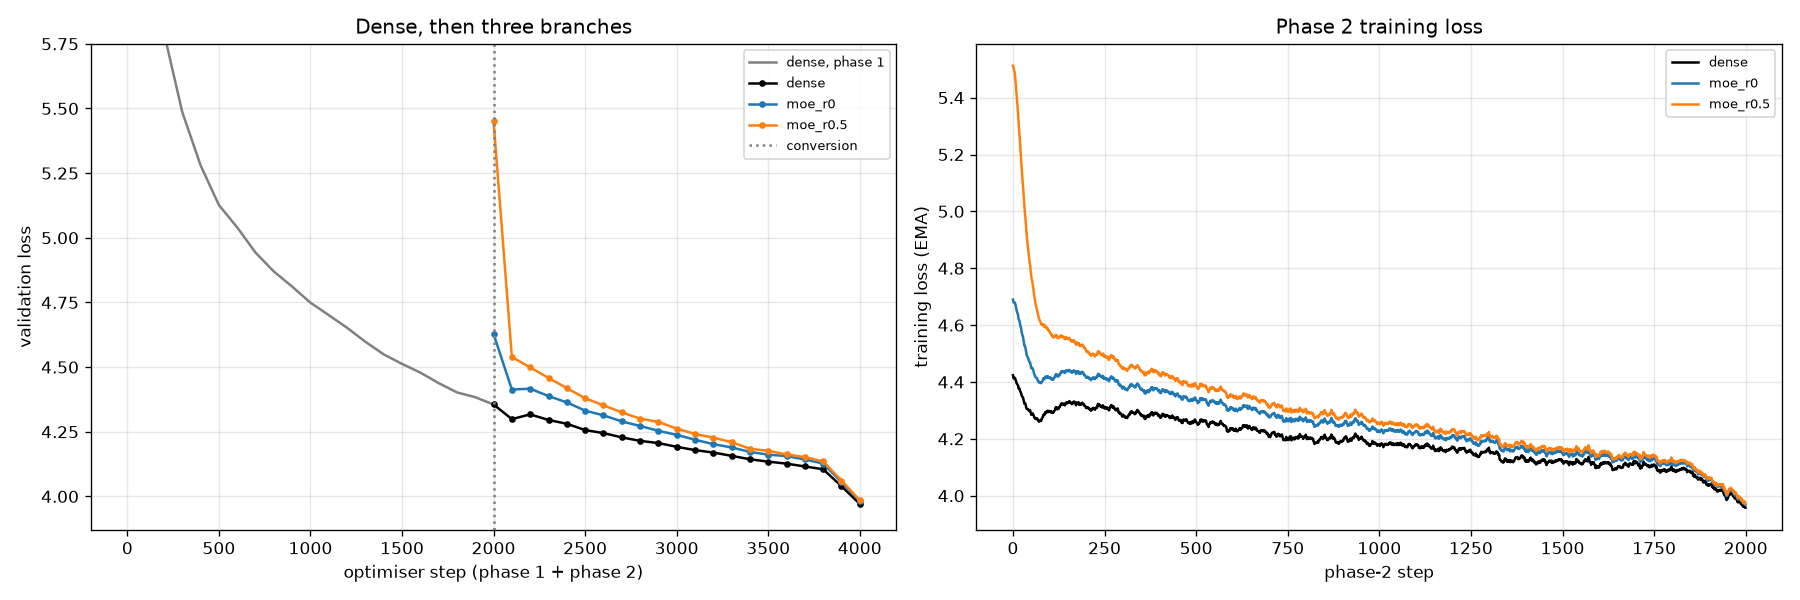

In [6]:
main(['--section', 'continue', '--log', 'runs/notebook/s14_3_continue.txt'])
display(Image('runs/session14/continue.png'))

## Task 4: load balance during training

device cuda, model D=384 L=8 FFN=1024; MoE 16 x 256, top-4; train.bin 60,000,000 tokens

4. LOAD BALANCE DURING TRAINING (Task 4)
  per optimiser step, per layer. Even load = 1/16 = 6.25% of routing slots.
  MaxVio: (busiest - even) / even. starved: experts under 10% of the even share. zero: no tokens at all.

  moe_r0
    step  MaxVio med  MaxVio max  starved  zero  bias range  seq aux
       0       0.785       1.283        0     0      0.0020    1.005
       1       0.548       0.748        0     0      0.0040    1.001
       4       0.583       0.842        0     0      0.0040    1.002
       9       0.570       0.877        0     0      0.0040    1.002
      24       0.494       0.627        0     0      0.0060    1.003
      49       0.308       0.528        0     0      0.0140    1.005
      99       0.189       0.328        0     0      0.0160    1.014
     249       0.125       0.238        0     0      0.0250    1.035
     499       0.129       0.310        0     0      0.028

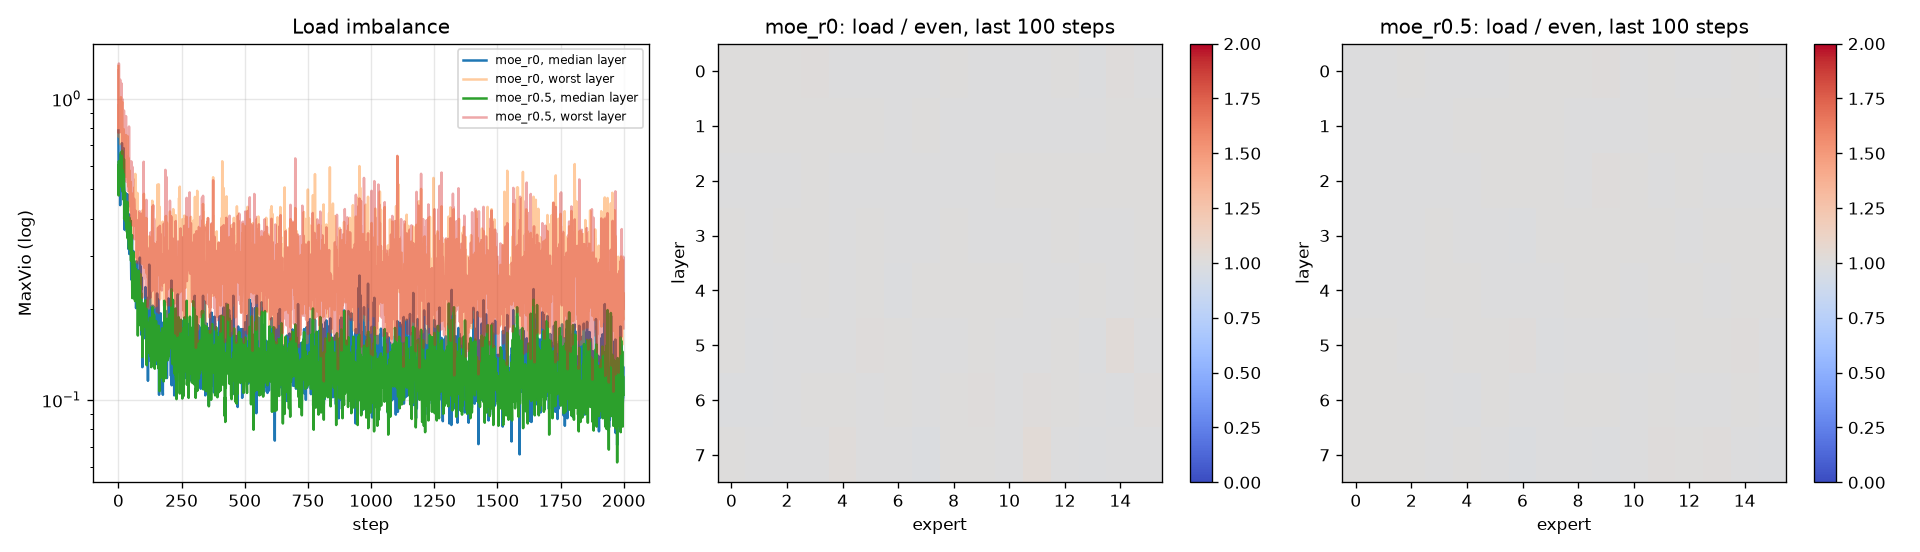

In [7]:
main(['--section', 'routing', '--log', 'runs/notebook/s14_4_routing.txt'])
display(Image('runs/session14/routing.png'))

## Task 5a: the same run with balancing off

device cuda, model D=384 L=8 FFN=1024; MoE 16 x 256, top-4; train.bin 60,000,000 tokens

5a. THE SAME MoE RUN WITH BALANCING SWITCHED OFF (Task 5, moe_r0.5, 600 steps)
  bias frozen at 0 and no sequence aux loss; same conversion, schedule and batches as the balanced run
    step        lr     loss     true    gnorm     val      ms    time
       0  1.00e-05   5.5124   5.5124    1.493  5.4509     345      1s
      60  6.10e-04   4.4990   4.4990    0.601       -     394     19s
     120  1.00e-03   4.4487   4.4487    0.571       -     403     43s
     180  1.00e-03   4.6205   4.6205    0.554       -     278     65s
     240  1.00e-03   4.4357   4.4357    0.532       -     421     88s
     300  1.00e-03   4.4584   4.4584    0.550  4.4293     392    111s
     360  1.00e-03   4.3563   4.3563    0.565       -     258    131s
     420  1.00e-03   4.3587   4.3587    0.535       -     266    152s
     480  1.00e-03   4.3534   4.3534    0.539       -     338    171s
     540  1.00e-03   4.2913  

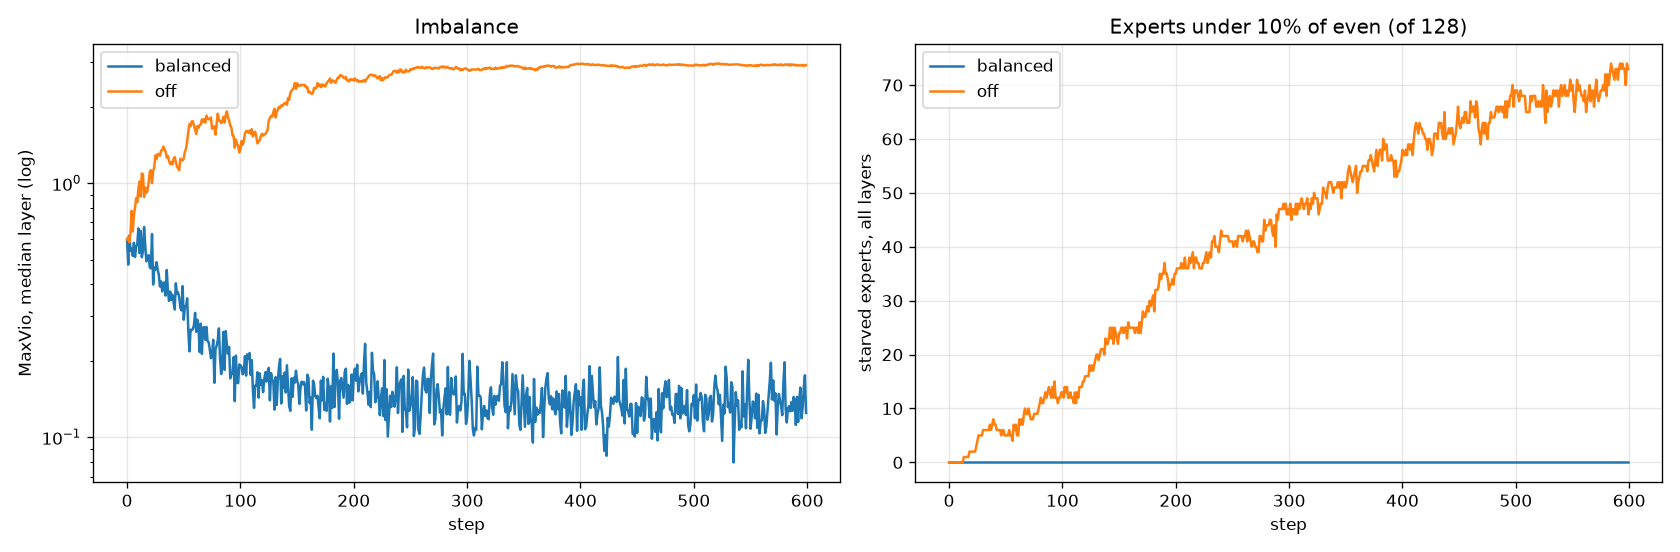

In [8]:
main(['--section', 'nobalance', '--log', 'runs/notebook/s14_5_nobalance.txt'])
display(Image('runs/session14/nobalance.png'))

## Task 5b: what did the experts learn?

device cuda, model D=384 L=8 FFN=1024; MoE 16 x 256, top-4; train.bin 60,000,000 tokens

5b. WHAT DID THE EXPERTS LEARN? (moe_r0.5 after training, Task 5)
  163,840 validation tokens, each token's category is that of the token itself.
  top share: share of the category's routing slots taken by its favourite expert (even = 6.25%)
  lift: for that expert, P(category | expert) / P(category). 1.0 = no preference.

  layer 0
  category         tokens  top expert  top share   lift
  whitespace         1.7%           1      24.1%   3.63
  punctuation       10.4%           3      11.5%   1.86
  digits             2.7%          14      10.1%   1.60
  function word     18.9%           0       9.5%   1.54
  Capitalised        7.4%          13       8.5%   1.29
  word start        31.9%           9       8.4%   1.31
  word piece        26.4%          11       8.4%   1.35
  other              0.6%          13      17.1%   2.61

  layer 4
  category         tokens  top expert  top share   lift
  whi

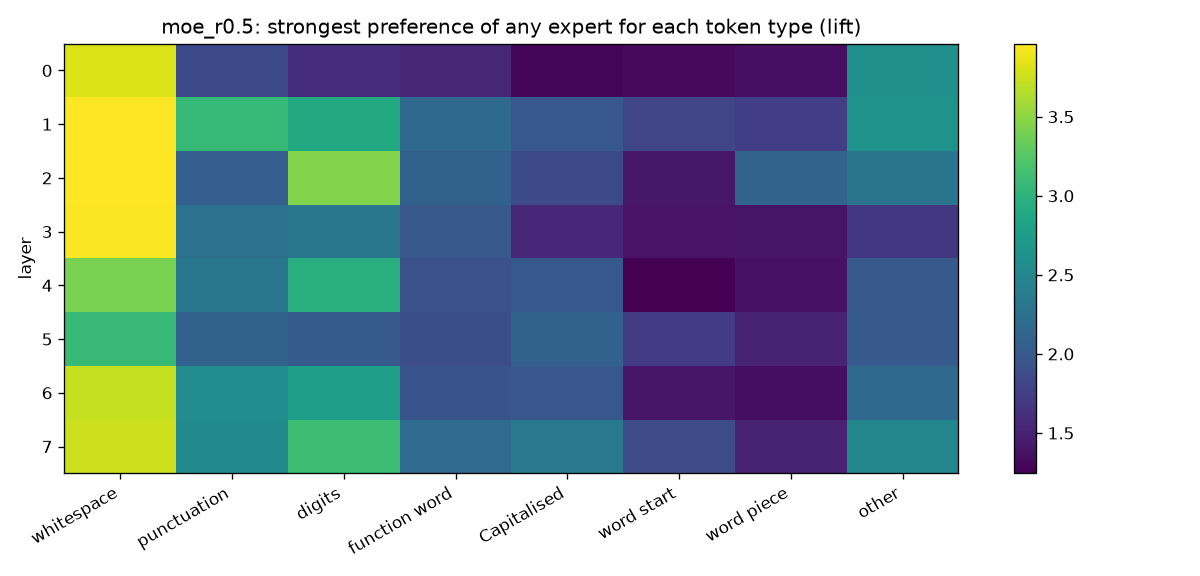

In [9]:
main(['--section', 'special', '--log', 'runs/notebook/s14_6_special.txt'])
display(Image('runs/session14/specialisation.png'))